In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

In [11]:
df = pd.read_csv("uber.csv")

In [12]:
df

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...,...,...
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,27804658,2009-06-29 00:42:00.00000078,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [13]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


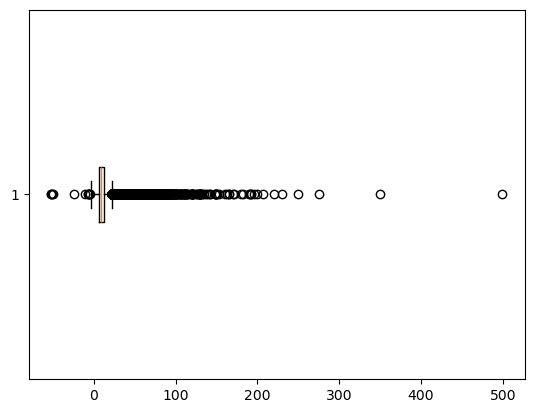

In [16]:
plt.boxplot(df['fare_amount'].dropna(),vert=False)
plt.show()

In [19]:
required = ["fare_amount","pickup_datetime","pickup_latitude","pickup_longitude","dropoff_latitude","dropoff_longitude","passenger_count"]

In [20]:
missing_col = [col for col in required if col not in df.columns]
if missing_col:
    raise ValueError(f"Missing expected columns : {missing_col}")

In [21]:
data = df[required].copy()
data["pickup_datetime"] = pd.to_datetime(data["pickup_datetime"],errors="coerce",utc=True)
data=data.dropna(subset=required)

In [22]:
for col in ["pickup_latitude","dropoff_latitude"]:
    data = data[data[col].between(-90,90)]
    
for col in ["pickup_longitude","dropoff_longitude"]:
    data = data[data[col].between(-180,180)]
    
    
coords = ["pickup_latitude","pickup_longitude","dropoff_latitude","dropoff_longitude"]

data = data[(data[coords] != 0).all(axis=1)]
data = data[(data["fare_amount"] > 0) & (data["fare_amount"] <= 200)]
data = data[data["passenger_count"].between(1,6)]

In [23]:
data["hour"] = data["pickup_datetime"].dt.hour
data["day_of_week"] = data["pickup_datetime"].dt.dayofweek
data["month"] = data["pickup_datetime"].dt.month
data["year"] = data["pickup_datetime"].dt.year

In [25]:
print(f"Rows before cleaing {len(df)}")
print(f"Rows after cleaning {len(data)}")

Rows before cleaing 200000
Rows after cleaning 195309


In [26]:
#Calculate haversine distance

lat1 = np.radians(data["pickup_latitude"])
lat2 = np.radians(data["dropoff_latitude"])

dlat = lat2 - lat1
dlon = np.radians(data["pickup_longitude"]-data["dropoff_longitude"])

In [27]:
a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
data["distance_km"]= 6370*2*np.arcsin(np.sqrt(a.clip(0,1)))

In [28]:
data = data[data["distance_km"].between(0.1, 100)].copy()
print("Rows after distance filtering:", len(data))


Rows after distance filtering: 192024


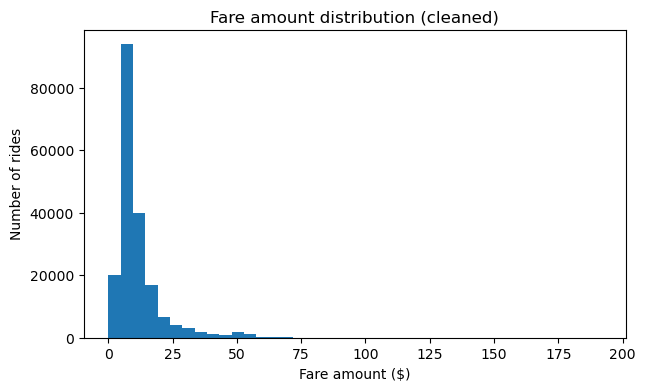

In [30]:
plt.figure(figsize=(7,4))
plt.hist(data["fare_amount"],bins=40)
plt.title("Fare amount distribution (cleaned)")
plt.xlabel("Fare amount ($)")
plt.ylabel("Number of rides")
plt.show()


In [31]:
sample = data.sample(n=min(3000, len(data)), random_state=42)

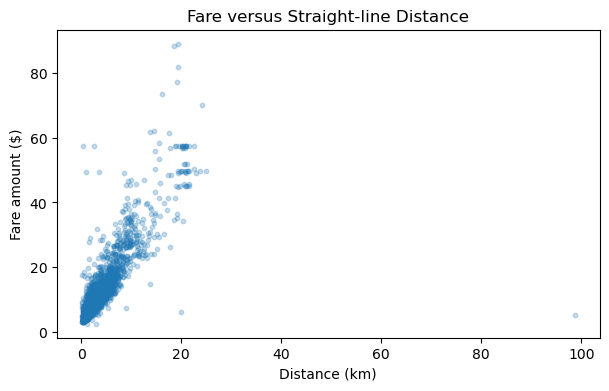

In [35]:
plt.figure(figsize=(7, 4))
plt.scatter(sample["distance_km"], sample["fare_amount"],
            alpha=0.25, s=10)
plt.title("Fare versus Straight-line Distance")
plt.xlabel("Distance (km)")
plt.ylabel("Fare amount ($)")
plt.show()

In [36]:
features = ["distance_km", "passenger_count", "hour",
            "day_of_week", "month", "year",
            "pickup_latitude", "pickup_longitude",
            "dropoff_latitude", "dropoff_longitude"]

X = data[features]
Y = data["fare_amount"]


In [37]:
#Apply train test split

X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [38]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [43]:
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)


In [44]:
print(f"features before pca {X_train_scaled.shape[1]}")
print(f"features after pca {X_train_pca.shape[1]}")

features before pca 10
features after pca 7


In [45]:
model_original = LinearRegression()
model_original.fit(X_train_scaled,Y_train)
pred_original = model_original.predict(X_test_scaled)

In [46]:
model_pca = LinearRegression()
model_pca.fit(X_train_pca,Y_train)
pred_pca = model_pca.predict(X_test_pca)

In [48]:

# Model without PCA
r2_original = r2_score(Y_test, pred_original)
rmse_original = np.sqrt(mean_squared_error(Y_test, pred_original))
mae_original = mean_absolute_error(Y_test, pred_original)

print("WITHOUT PCA")
print("R2 Score:", round(r2_original, 3))
print("RMSE:", round(rmse_original, 3))
print("MAE:", round(mae_original, 3))

# Model with PCA
r2_pca = r2_score(Y_test, pred_pca)
rmse_pca = np.sqrt(mean_squared_error(Y_test, pred_pca))
mae_pca = mean_absolute_error(Y_test, pred_pca)

print("\nWITH PCA")
print("R2 Score:", round(r2_pca, 3))
print("RMSE:", round(rmse_pca, 3))
print("MAE:", round(mae_pca, 3))


WITHOUT PCA
R2 Score: 0.762
RMSE: 4.627
MAE: 2.246

WITH PCA
R2 Score: 0.761
RMSE: 4.629
MAE: 2.257
